In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # silence XLA warnings about the CUDA driver version

import numpy as np
import optax
import jax.numpy as jnp
import equinox as eqx
import jax
import itertools

from jax import random, vmap
from jax.lax import scan
from drums.data import preprocessing, spectrum
from drums.data.quadrilateral_drums import polygon_area

import matplotlib.pyplot as plt

%config InlineBackend.figure_format='retina'

In [2]:
def align(v1, v2):
    """Centre v1 and v2 and rotate/reflect v2 onto v1 (orthogonal Procrustes)."""
    v1_ = v1 - jnp.mean(v1, axis=0, keepdims=True)
    v2_ = v2 - jnp.mean(v2, axis=0, keepdims=True)
    U, S, Vt = jnp.linalg.svd(v2_.T @ v1_, full_matrices=False)
    R = U @ Vt
    return v1_, v2_ @ R

@eqx.filter_jit
def get_best_alignment(v1, v2, idx):
    distances = vmap(lambda ind: distance(v1, v2[ind]))(idx)
    best_n = jnp.argmin(distances)
    v1_, v2_ = vmap(lambda ind: align(v1, v2[ind]))(idx)
    return v1_[best_n], v2_[best_n]

def distance(target, prediction):
    target_, prediction_ = align(target, prediction)
    return jnp.mean(jnp.linalg.norm(target_ - prediction_, axis=1))

def invariant_distance(target, prediction, idx):
    return jnp.min(vmap(lambda ind: distance(target, prediction[ind]))(idx))

def get_sensitivity(carry, ind, idx):
    spectra, perimeters = carry
    error_s = 2*jnp.linalg.norm(spectra[ind[0]] - spectra[ind[1]]) / (jnp.linalg.norm(spectra[ind[0]]) + jnp.linalg.norm(spectra[ind[1]]))
    error_p = 2*invariant_distance(perimeters[ind[0]], perimeters[ind[1]], idx) / (jnp.mean(jnp.linalg.norm(perimeters[ind[0]] - jnp.mean(perimeters[ind[0]], axis=0, keepdims=True), axis=1)) + jnp.mean(jnp.linalg.norm(perimeters[ind[1]] - jnp.mean(perimeters[ind[1]], axis=0, keepdims=True), axis=1)))
    return [spectra, perimeters], jnp.array([error_s, error_p])

To generate a dataset run `python src/drums/data/datasets_collection.py <name> <folder>`; it saves `<name>.npz` with 1000 drums (`perimeters` and the 30 lowest eigenvalues `spectra`) in `<folder>`. The names are:
- `triangle_drums`: random triangles with all angles at least 30 degrees;
- `convex_quadrilateral_drums`: random convex quadrilaterals;
- `mixed_quadrilateral_drums`: random quadrilaterals, about half of them non-convex (`is_convex` tells which).
- `gww_drums`: one of the two isospectral drums of Gordon, Webb and Wolpert (each with probability 1/2, `domain` tells which), with independent uniform noise in $[-0.1, 0.1]$ added to every vertex coordinate.
- `isospectral_drums`: exactly isospectral pairs of drums from Buser, Conway, Doyle and Semmler, "Some planar isospectral domains" (https://arxiv.org/abs/1005.1839). A random triangle (all angles at least 30 degrees) is drawn and seven copies of it, neighbours being mirror images in their common edge, are stitched into two different 9-gons (the GWW topology) with the same spectrum. The sample is one of them (each with probability 1/2); `twin_perimeters` are the vertices of the other one and `triangle` is the triangle they are built from. `domain` tells which one the sample is: 0 for the canonical drum of the pair, 1 for the other one (the corners of the triangle are labelled so that the angle at the first corner is not smaller than at the third; without it the names of the two drums would be exchanged at random).

In [3]:
triangles = jnp.load('triangle_drums.npz')
triangles_perimeters = jnp.array(triangles['perimeters'])
triangles_spectra = jnp.array(triangles['spectra'])

convex_quadrilaterals = jnp.load('convex_quadrilateral_drums.npz')
convex_quadrilaterals_perimeters = jnp.array(convex_quadrilaterals['perimeters'])
convex_quadrilaterals_spectra = jnp.array(convex_quadrilaterals['spectra'])

mixed_quadrilaterals = jnp.load('mixed_quadrilateral_drums.npz')
mixed_quadrilaterals_perimeters = jnp.array(mixed_quadrilaterals['perimeters'])
mixed_quadrilaterals_spectra = jnp.array(mixed_quadrilaterals['spectra'])

gww = jnp.load('gww_drums.npz')
gww_perimeters = jnp.array(gww['perimeters'])
gww_spectra = jnp.array(gww['spectra'])

N_samples = mixed_quadrilaterals_perimeters.shape[0]
ind = jnp.array([*filter(lambda a: a[0] > a[1], itertools.product(range(N_samples), repeat=2))])

# Triangles

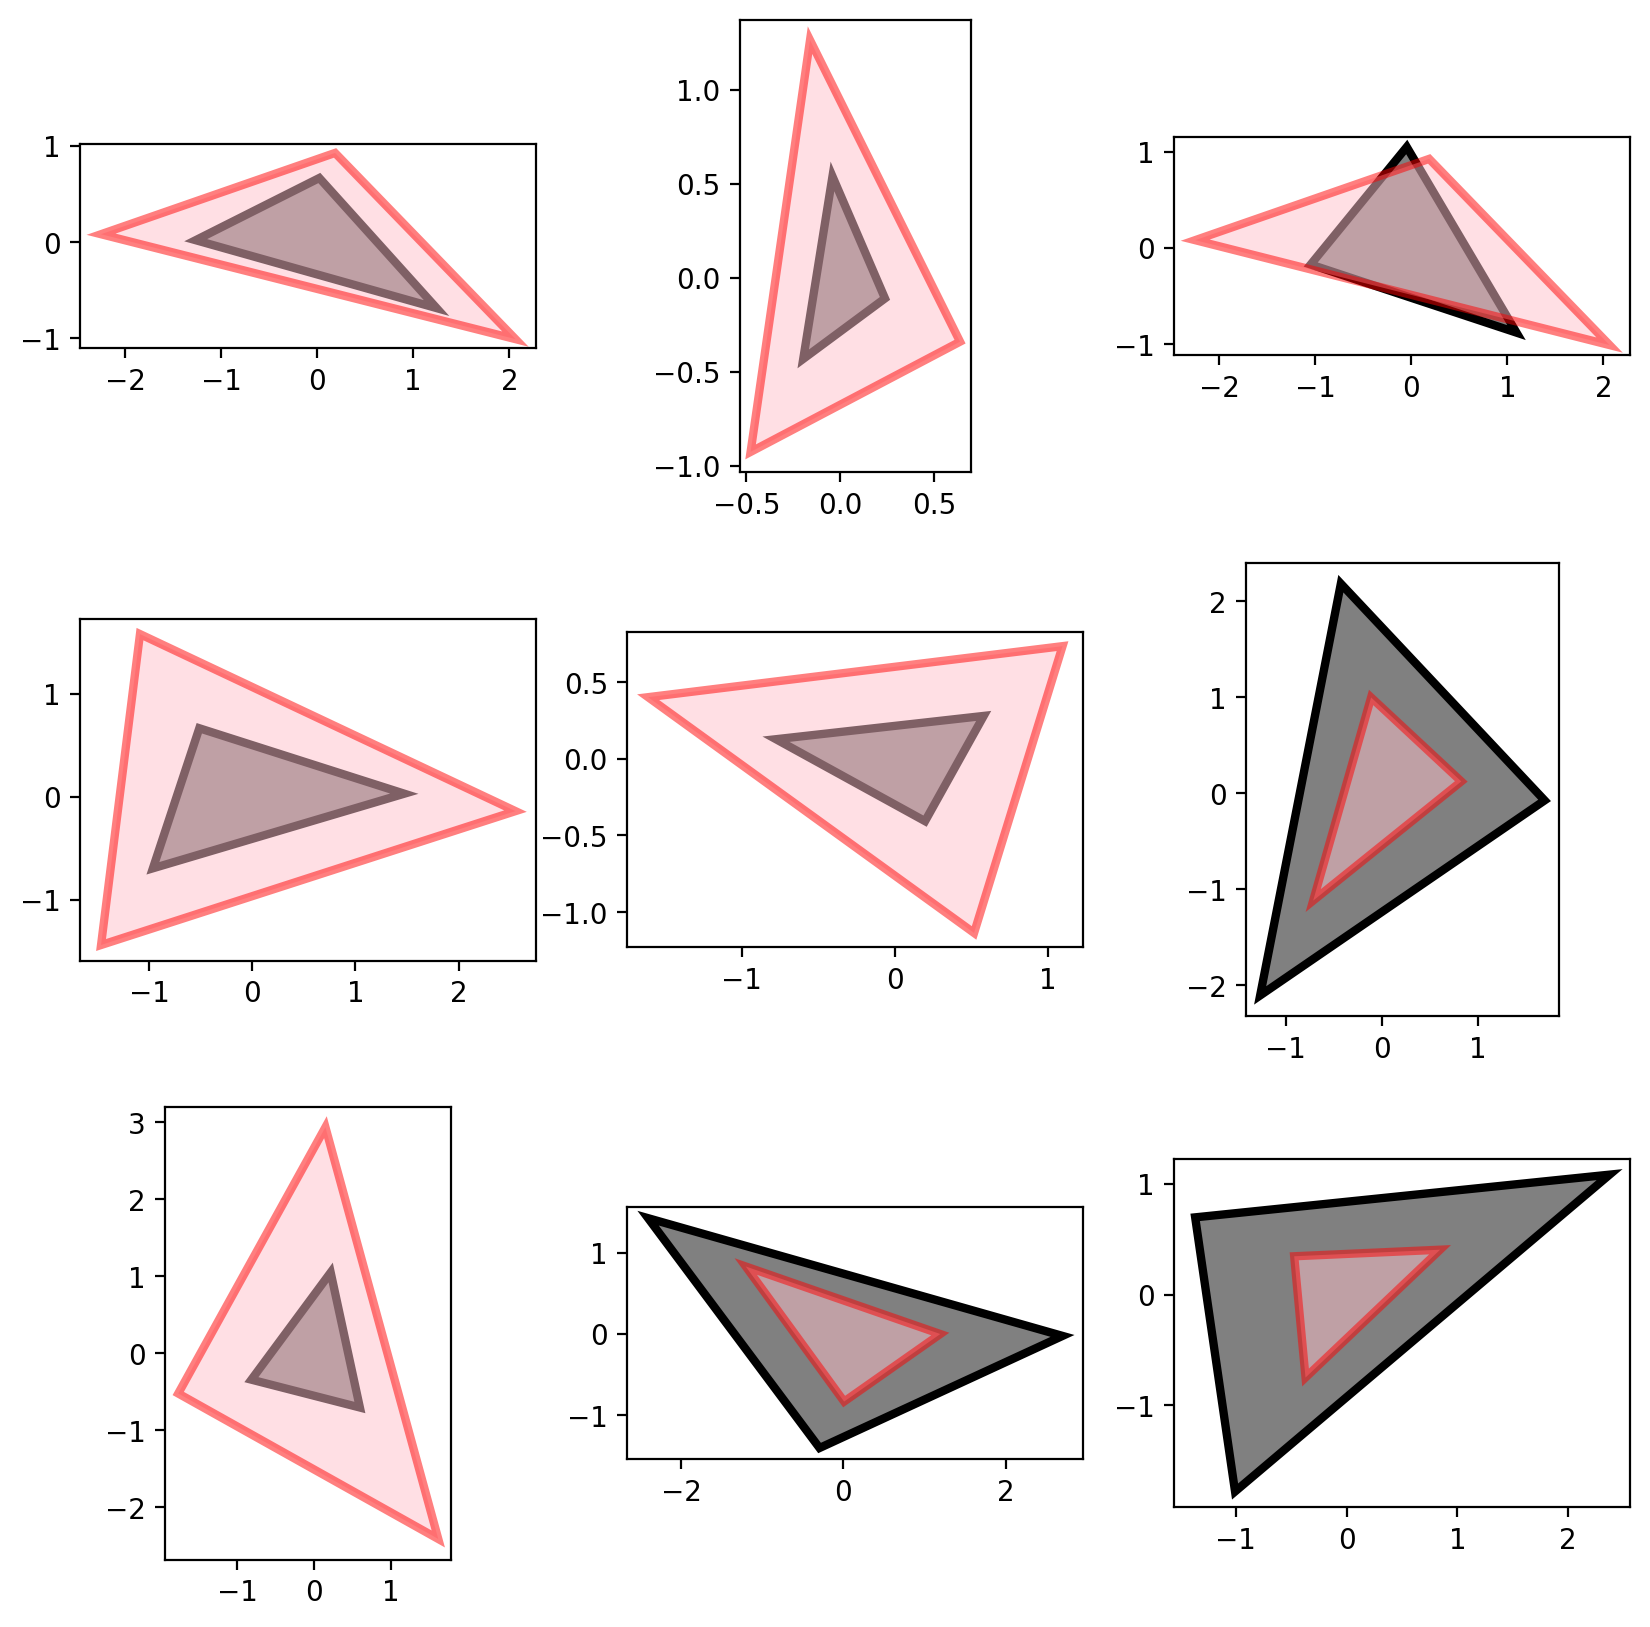

In [4]:
perimeters, spectra = triangles_perimeters, triangles_spectra

N_v = perimeters.shape[1]
idx = preprocessing.augment(np.arange(N_v, dtype=float)[:, None])[..., 0].astype(int)

key = random.PRNGKey(334)
indices = random.choice(key, perimeters.shape[0], shape=(9, 2))

fig, ax = plt.subplots(3, 3, figsize=(10, 10))
ax = ax.reshape(-1,)
for i in range(9):
    v1, v2 = get_best_alignment(perimeters[indices[i][0]], perimeters[indices[i][1]], idx)
    ax[i].fill(v2[:, 0], v2[:, 1], facecolor="grey", edgecolor="black", linewidth=3)
    ax[i].fill(v1[:, 0], v1[:, 1], facecolor="pink", edgecolor="red", linewidth=3, alpha=0.5)
    ax[i].set_aspect("equal")

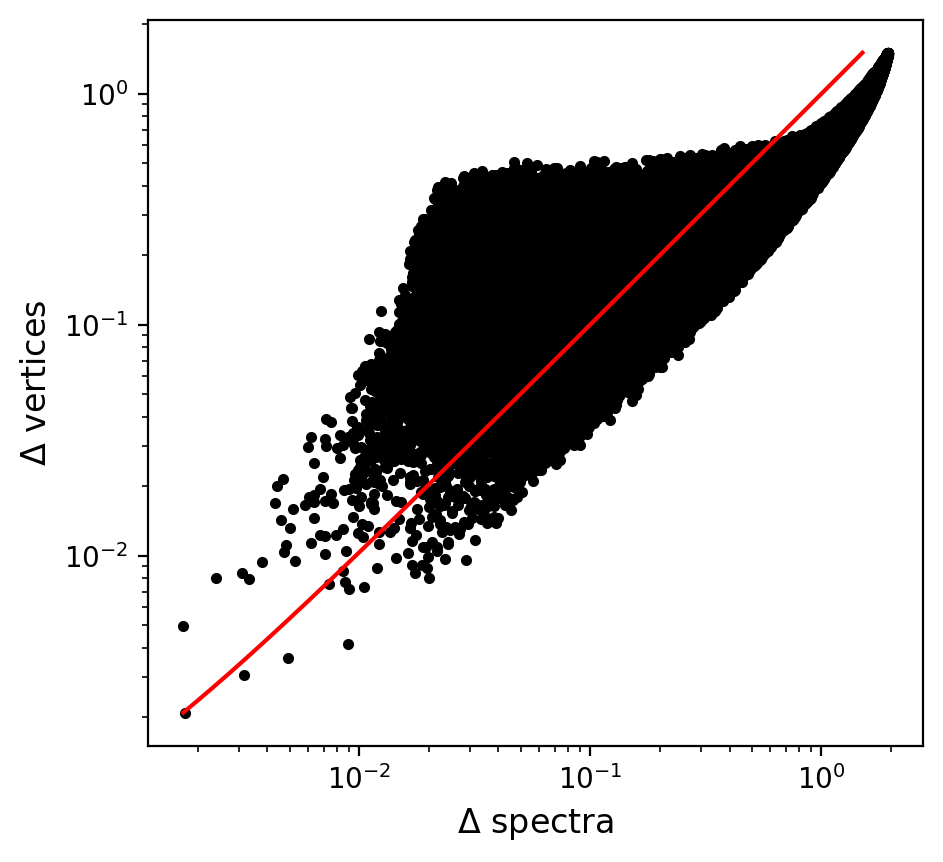

In [5]:
get_sensitivity_ = lambda a, b: get_sensitivity(a, b, idx)
_, errors = scan(get_sensitivity_, [spectra, perimeters], ind)

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_yscale("log")
ax.set_xscale("log")
ax.plot(errors[:, 0], errors[:, 1], ".", color='black')
min_x, max_x, min_y, max_y = jnp.min(errors[:, 0]), jnp.max(errors[:, 0]), jnp.min(errors[:, 1]), jnp.max(errors[:, 1])
if max_x + min_y - min_x < max_y:
    a, b = [min_x, max_x], [min_y, max_x + min_y - min_x]
else:
    a, b = [min_x, max_y - min_y + min_x], [min_y, max_y]

N_x = int(1e7)
x = jnp.linspace(a[0], a[1], N_x)
y = (b[1] - b[0]) * (x - a[0]) / (a[1] - a[0]) + b[0]
ax.plot(x, y, color="red")
ax.set_aspect("equal")
ax.set_xlabel("$\\Delta$ spectra", fontsize='large')
ax.set_ylabel("$\\Delta$ vertices", fontsize='large');

# Convex quadrilaterals

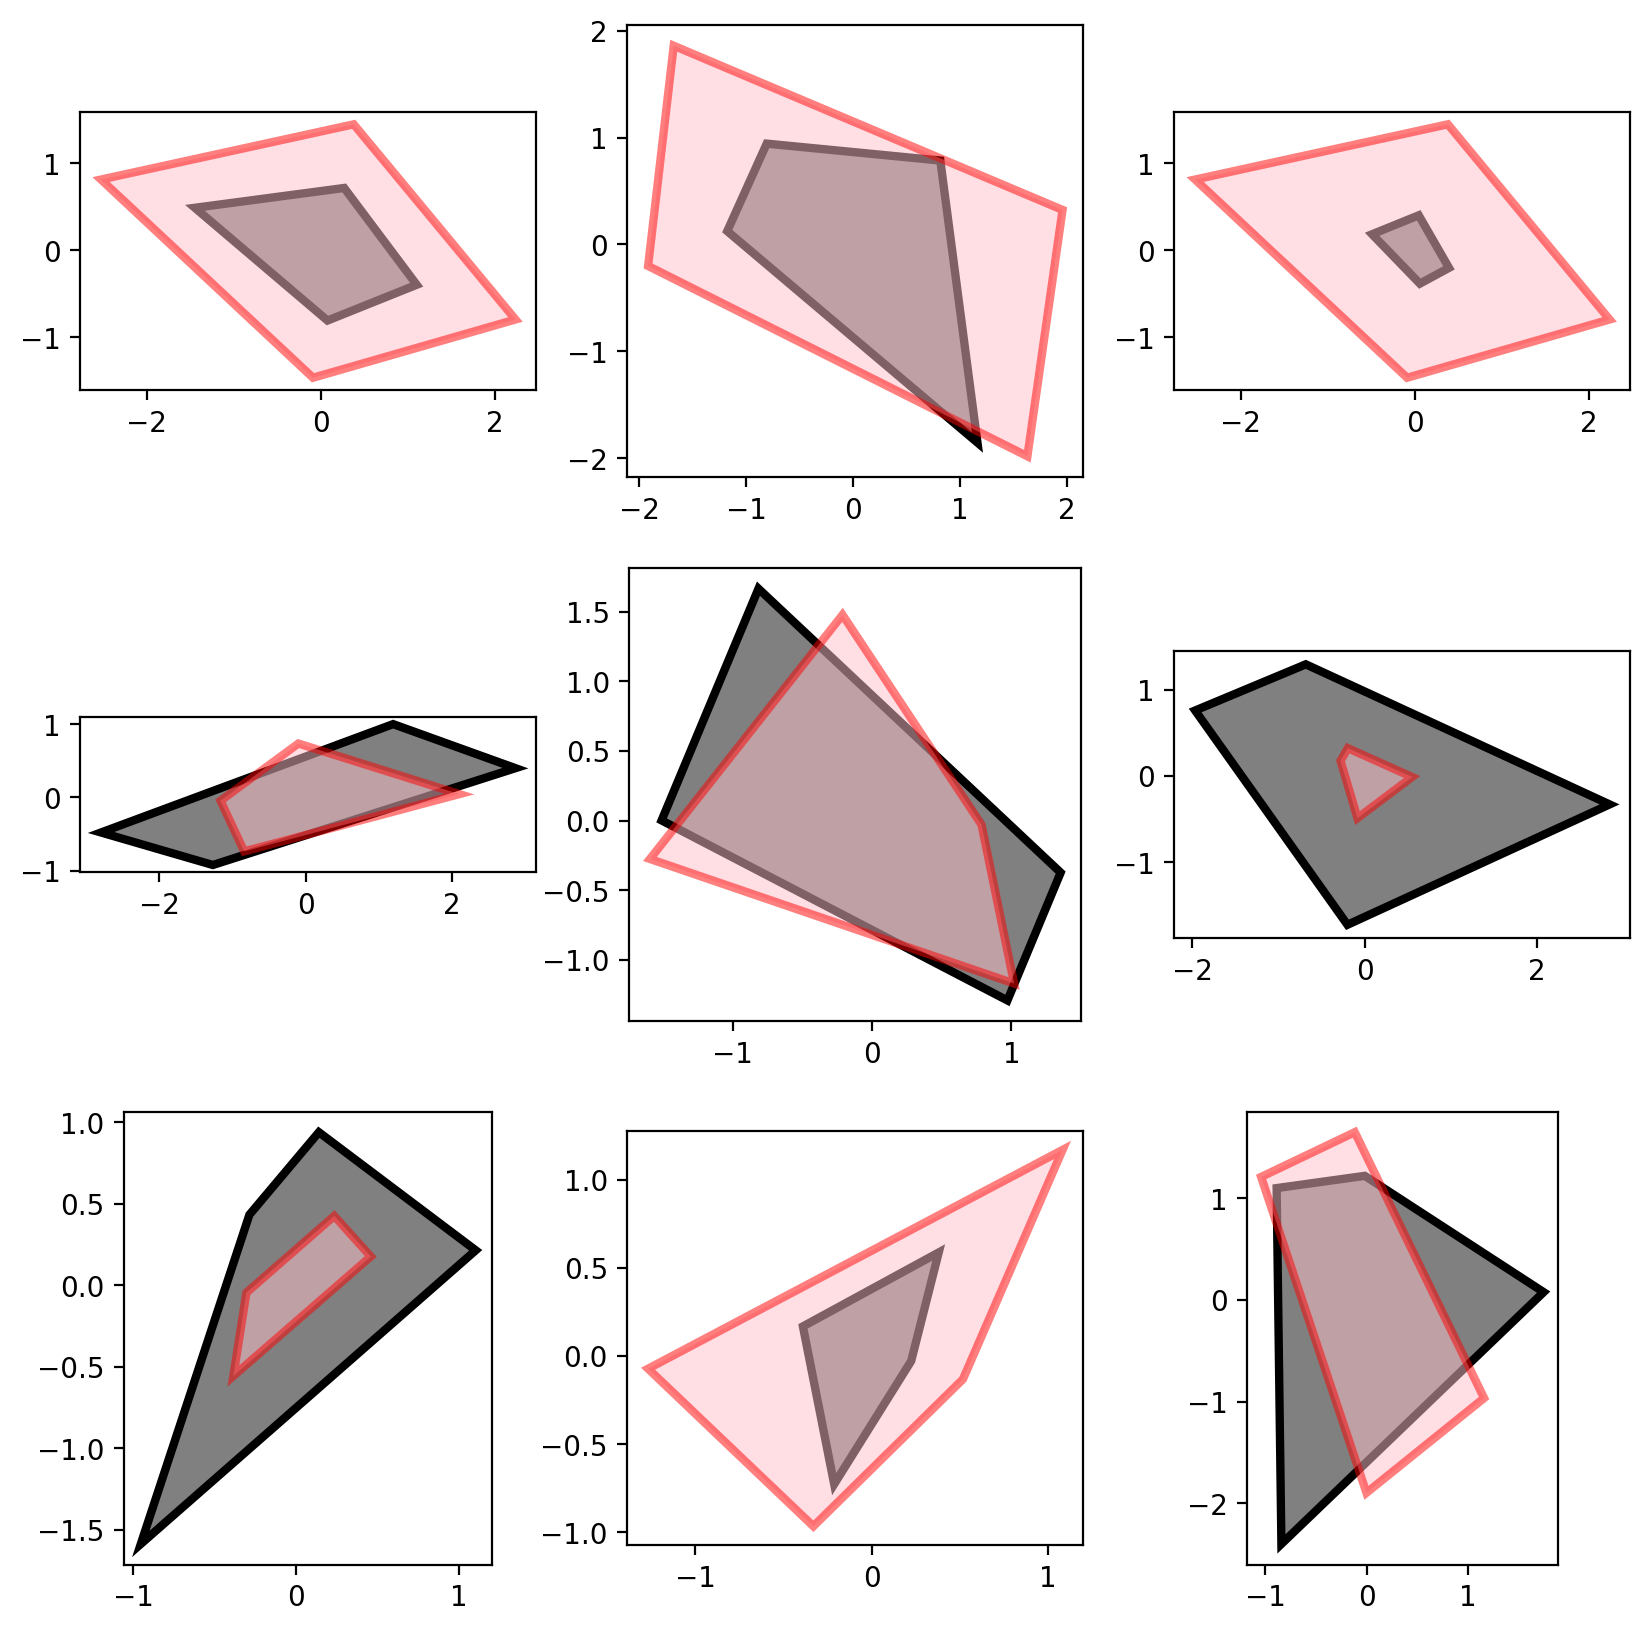

In [6]:
perimeters, spectra = convex_quadrilaterals_perimeters, convex_quadrilaterals_spectra

N_v = perimeters.shape[1]
idx = preprocessing.augment(np.arange(N_v, dtype=float)[:, None])[..., 0].astype(int)

key = random.PRNGKey(334)
indices = random.choice(key, perimeters.shape[0], shape=(9, 2))

fig, ax = plt.subplots(3, 3, figsize=(10, 10))
ax = ax.reshape(-1,)
for i in range(9):
    v1, v2 = get_best_alignment(perimeters[indices[i][0]], perimeters[indices[i][1]], idx)
    ax[i].fill(v2[:, 0], v2[:, 1], facecolor="grey", edgecolor="black", linewidth=3)
    ax[i].fill(v1[:, 0], v1[:, 1], facecolor="pink", edgecolor="red", linewidth=3, alpha=0.5)
    ax[i].set_aspect("equal")

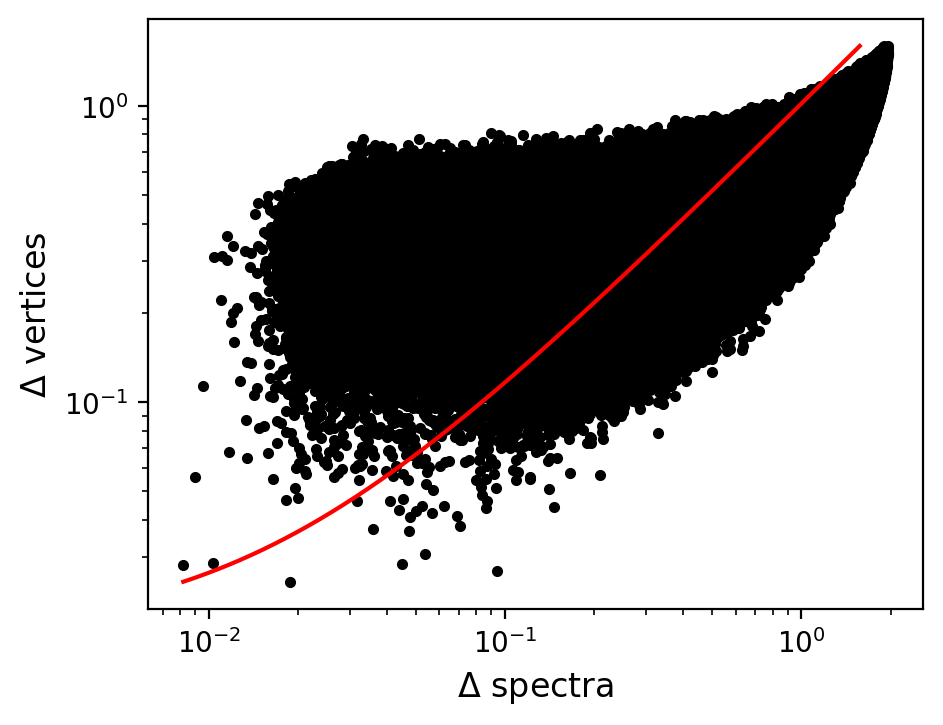

In [7]:
get_sensitivity_ = lambda a, b: get_sensitivity(a, b, idx)
_, errors = scan(get_sensitivity_, [spectra, perimeters], ind)

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_yscale("log")
ax.set_xscale("log")
ax.plot(errors[:, 0], errors[:, 1], ".", color='black')
min_x, max_x, min_y, max_y = jnp.min(errors[:, 0]), jnp.max(errors[:, 0]), jnp.min(errors[:, 1]), jnp.max(errors[:, 1])
if max_x + min_y - min_x < max_y:
    a, b = [min_x, max_x], [min_y, max_x + min_y - min_x]
else:
    a, b = [min_x, max_y - min_y + min_x], [min_y, max_y]

N_x = int(1e7)
x = jnp.linspace(a[0], a[1], N_x)
y = (b[1] - b[0]) * (x - a[0]) / (a[1] - a[0]) + b[0]
ax.plot(x, y, color="red")
ax.set_aspect("equal")
ax.set_xlabel("$\\Delta$ spectra", fontsize='large')
ax.set_ylabel("$\\Delta$ vertices", fontsize='large');

# Mixed quadrilaterals

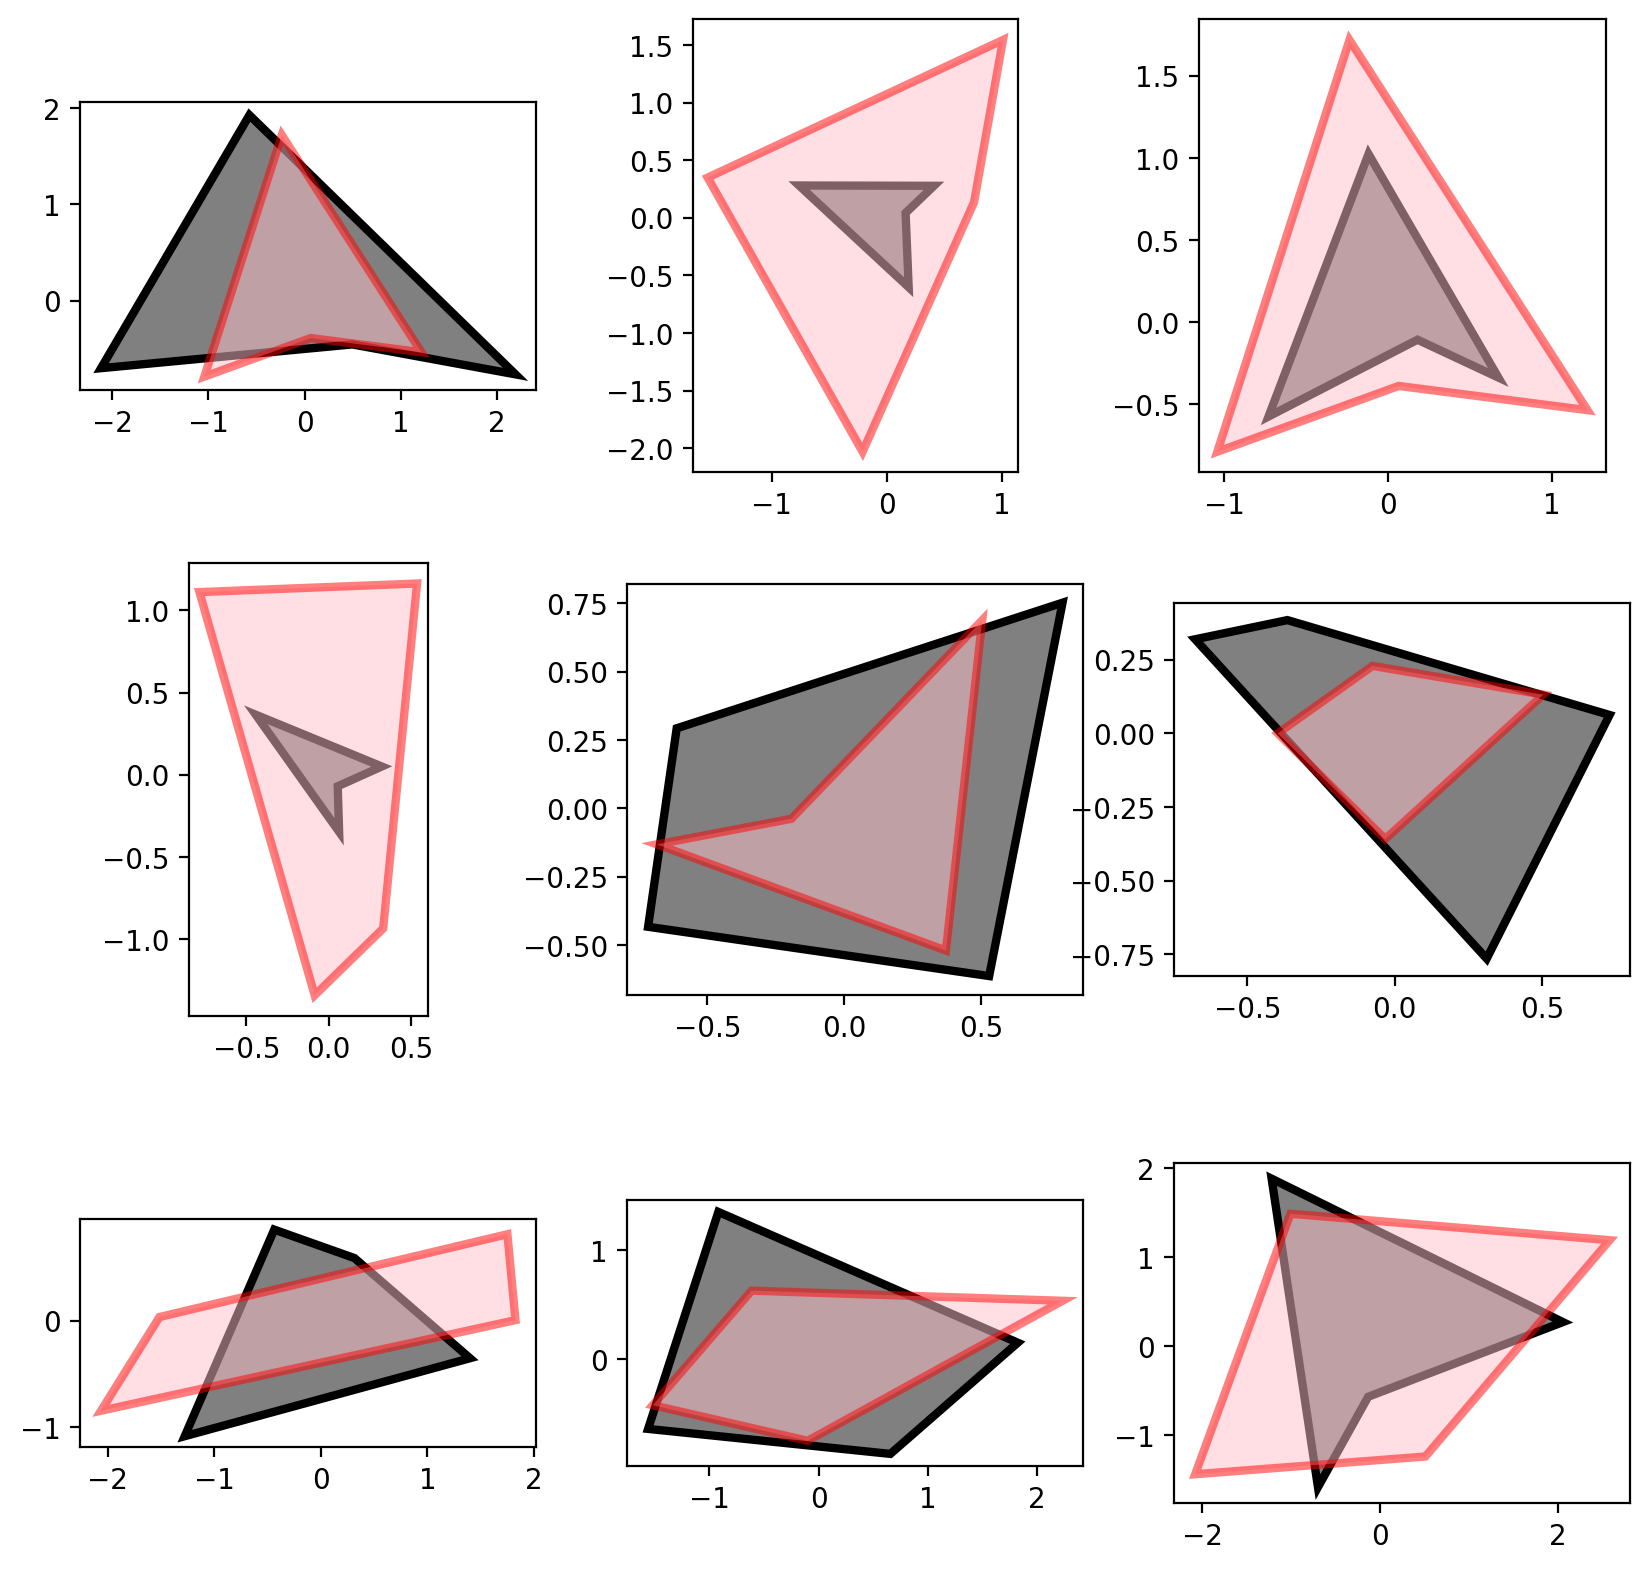

In [8]:
perimeters, spectra = mixed_quadrilaterals_perimeters, mixed_quadrilaterals_spectra

N_v = perimeters.shape[1]
idx = preprocessing.augment(np.arange(N_v, dtype=float)[:, None])[..., 0].astype(int)

key = random.PRNGKey(334)
indices = random.choice(key, perimeters.shape[0], shape=(9, 2))

fig, ax = plt.subplots(3, 3, figsize=(10, 10))
ax = ax.reshape(-1,)
for i in range(9):
    v1, v2 = get_best_alignment(perimeters[indices[i][0]], perimeters[indices[i][1]], idx)
    ax[i].fill(v2[:, 0], v2[:, 1], facecolor="grey", edgecolor="black", linewidth=3)
    ax[i].fill(v1[:, 0], v1[:, 1], facecolor="pink", edgecolor="red", linewidth=3, alpha=0.5)
    ax[i].set_aspect("equal")

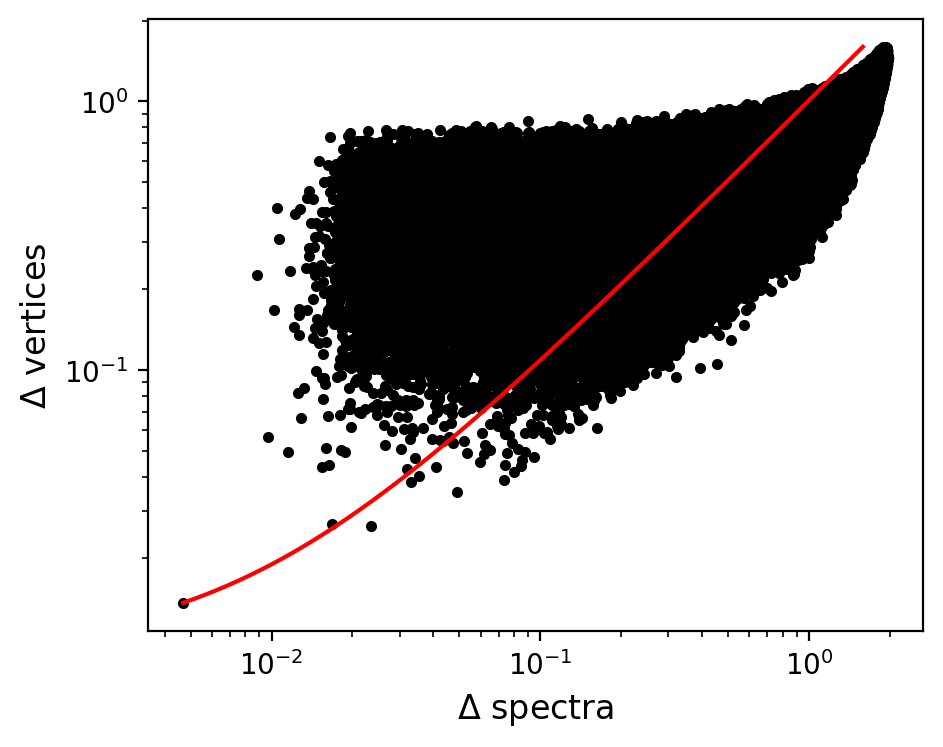

In [9]:
get_sensitivity_ = lambda a, b: get_sensitivity(a, b, idx)
_, errors = scan(get_sensitivity_, [spectra, perimeters], ind)

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_yscale("log")
ax.set_xscale("log")
ax.plot(errors[:, 0], errors[:, 1], ".", color='black')
min_x, max_x, min_y, max_y = jnp.min(errors[:, 0]), jnp.max(errors[:, 0]), jnp.min(errors[:, 1]), jnp.max(errors[:, 1])
if max_x + min_y - min_x < max_y:
    a, b = [min_x, max_x], [min_y, max_x + min_y - min_x]
else:
    a, b = [min_x, max_y - min_y + min_x], [min_y, max_y]

N_x = int(1e7)
x = jnp.linspace(a[0], a[1], N_x)
y = (b[1] - b[0]) * (x - a[0]) / (a[1] - a[0]) + b[0]
ax.plot(x, y, color="red")
ax.set_aspect("equal")
ax.set_xlabel("$\\Delta$ spectra", fontsize='large')
ax.set_ylabel("$\\Delta$ vertices", fontsize='large');

# Gordon, Webb, Wolpert isospectral drums

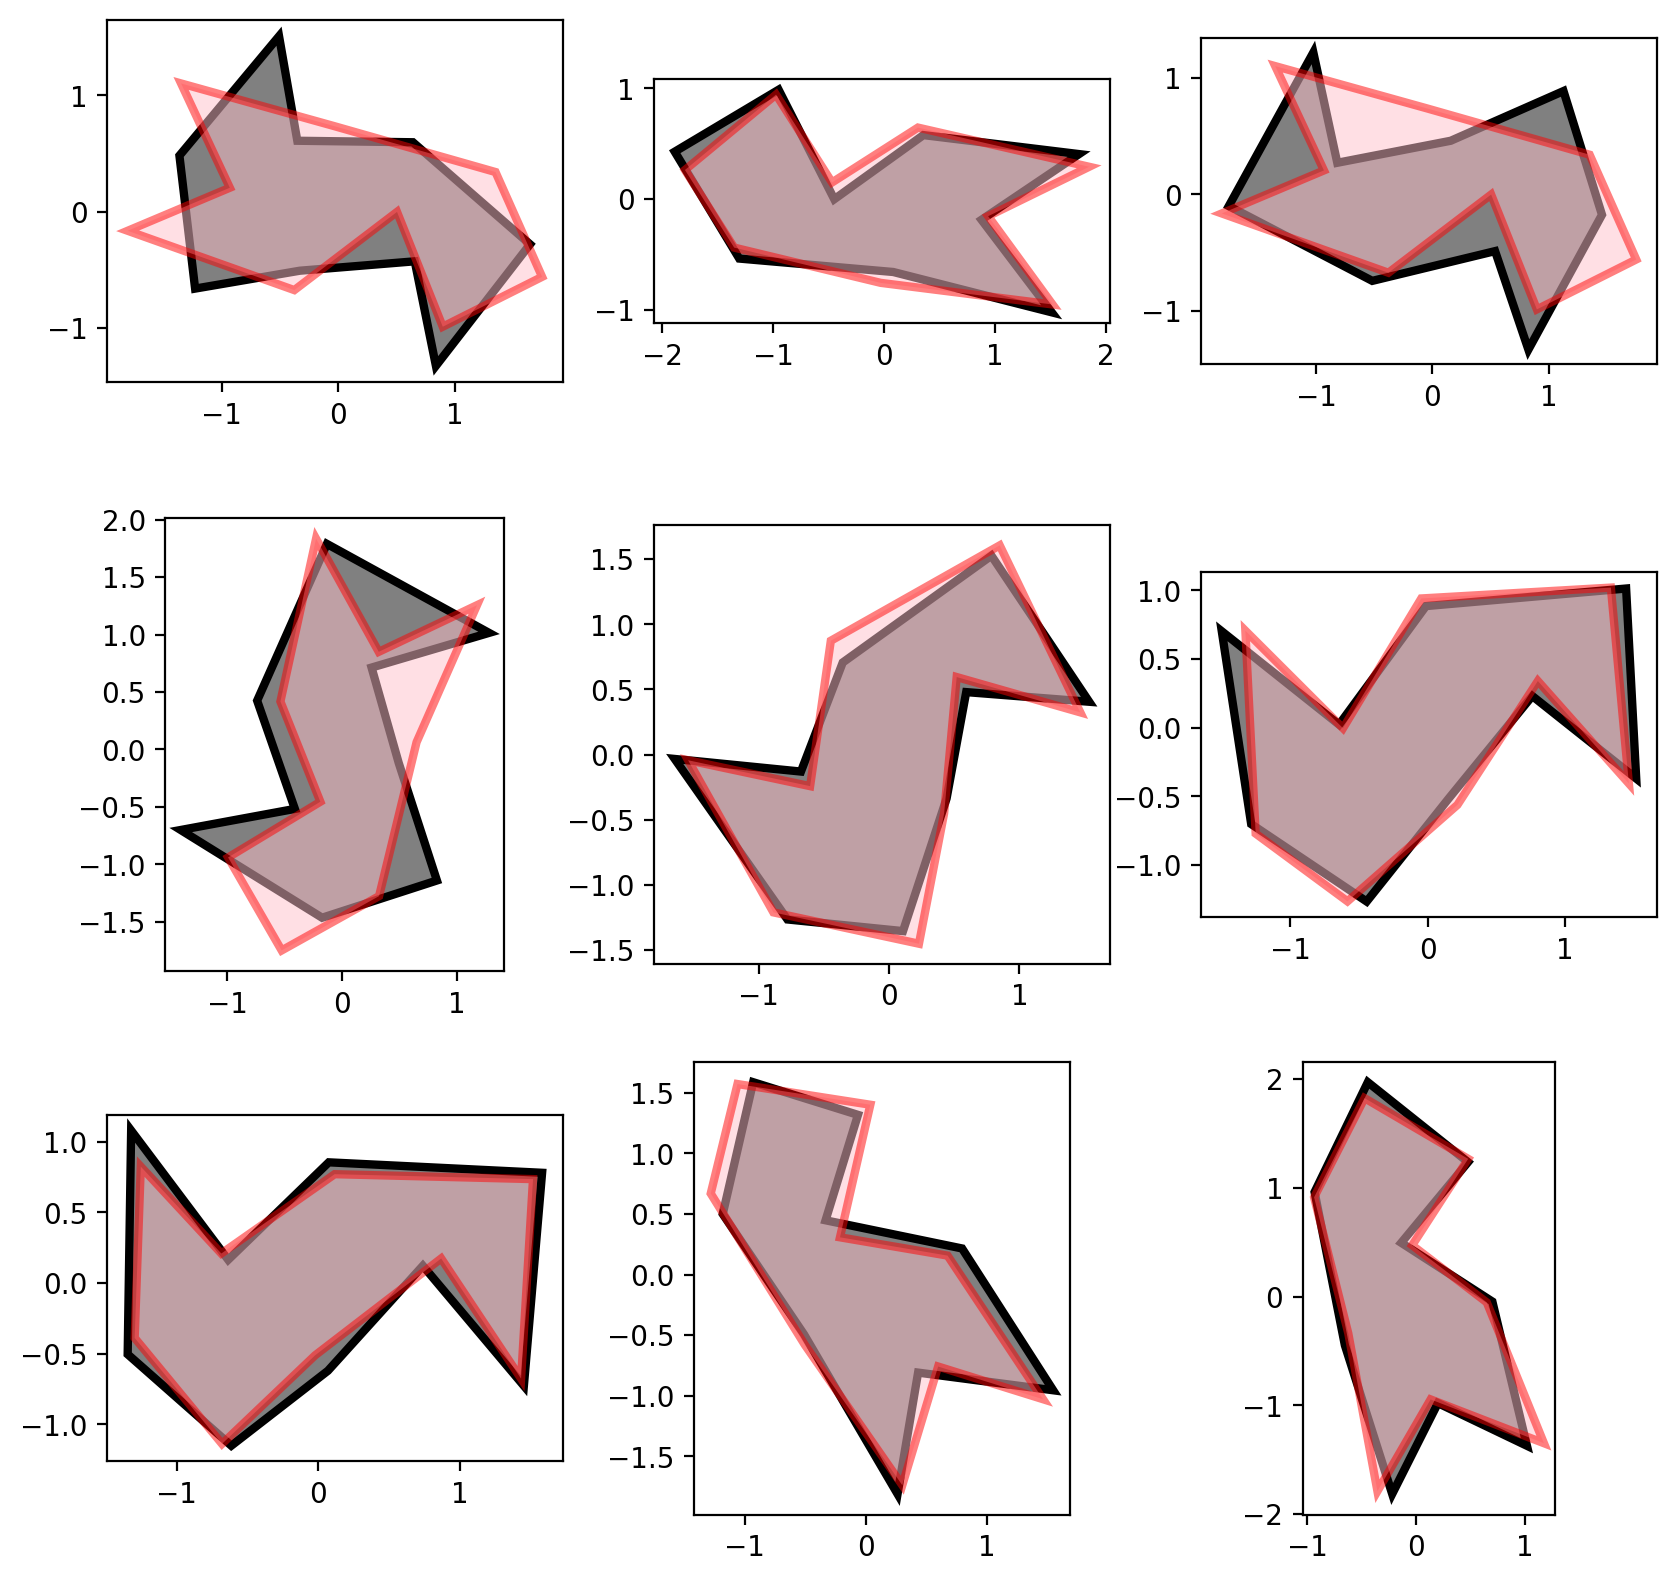

In [10]:
perimeters, spectra = gww_perimeters, gww_spectra

N_v = perimeters.shape[1]
idx = preprocessing.augment(np.arange(N_v, dtype=float)[:, None])[..., 0].astype(int)

key = random.PRNGKey(334)
indices = random.choice(key, perimeters.shape[0], shape=(9, 2))

fig, ax = plt.subplots(3, 3, figsize=(10, 10))
ax = ax.reshape(-1,)
for i in range(9):
    v1, v2 = get_best_alignment(perimeters[indices[i][0]], perimeters[indices[i][1]], idx)
    ax[i].fill(v2[:, 0], v2[:, 1], facecolor="grey", edgecolor="black", linewidth=3)
    ax[i].fill(v1[:, 0], v1[:, 1], facecolor="pink", edgecolor="red", linewidth=3, alpha=0.5)
    ax[i].set_aspect("equal")

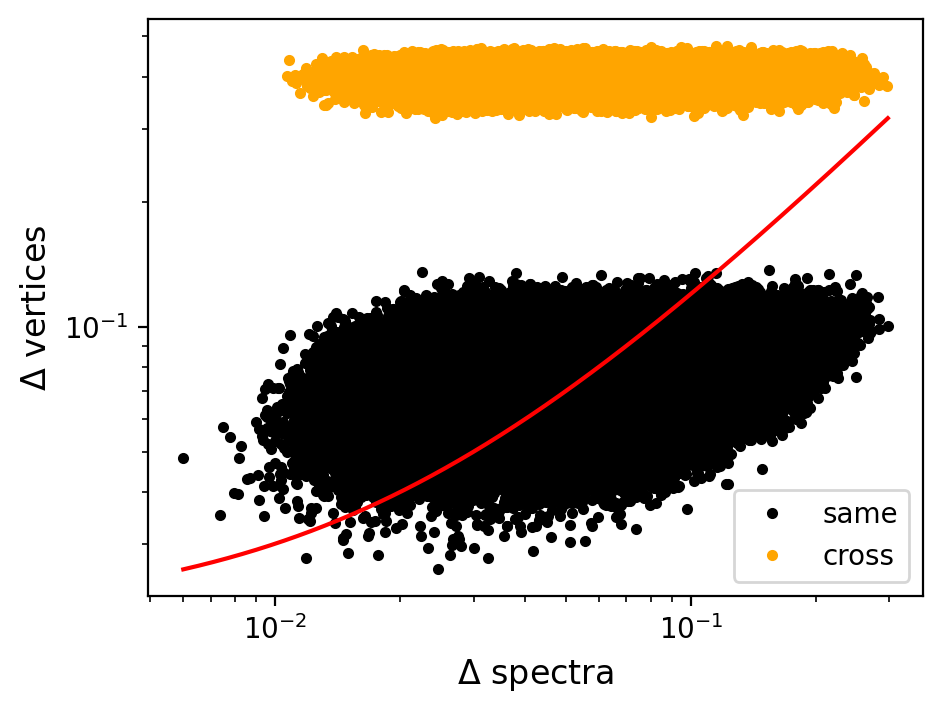

In [11]:
get_sensitivity_ = lambda a, b: get_sensitivity(a, b, idx)
_, errors = scan(get_sensitivity_, [spectra, perimeters], ind)

domains = jnp.array(gww['domain'])
cross_samples = domains[ind[:, 0]] != domains[ind[:, 1]]

same_base_drum = jnp.logical_not(cross_samples)
distinct_base_drums = cross_samples


fig, ax = plt.subplots(figsize=(5, 5))
ax.set_yscale("log")
ax.set_xscale("log")

same_errors = errors[same_base_drum]
distinc_errors = errors[distinct_base_drums]
ax.plot(same_errors[:, 0], same_errors[:, 1], ".", color='black', label='same')
ax.plot(distinc_errors[:, 0], distinc_errors[:, 1], ".", color='orange', label='cross')
min_x, max_x, min_y, max_y = jnp.min(errors[:, 0]), jnp.max(errors[:, 0]), jnp.min(errors[:, 1]), jnp.max(errors[:, 1])
if max_x + min_y - min_x < max_y:
    a, b = [min_x, max_x], [min_y, max_x + min_y - min_x]
else:
    a, b = [min_x, max_y - min_y + min_x], [min_y, max_y]

N_x = int(1e7)
x = jnp.linspace(a[0], a[1], N_x)
y = (b[1] - b[0]) * (x - a[0]) / (a[1] - a[0]) + b[0]
ax.plot(x, y, color="red")
ax.set_aspect("equal")
ax.set_xlabel("$\\Delta$ spectra", fontsize='large')
ax.set_ylabel("$\\Delta$ vertices", fontsize='large')
ax.legend(loc="lower right");

# Buser, Conway, Doyle, Semmler

In [12]:
isospectral = jnp.load('isospectral_drums.npz')
isospectral_spectrum = isospectral['spectra']

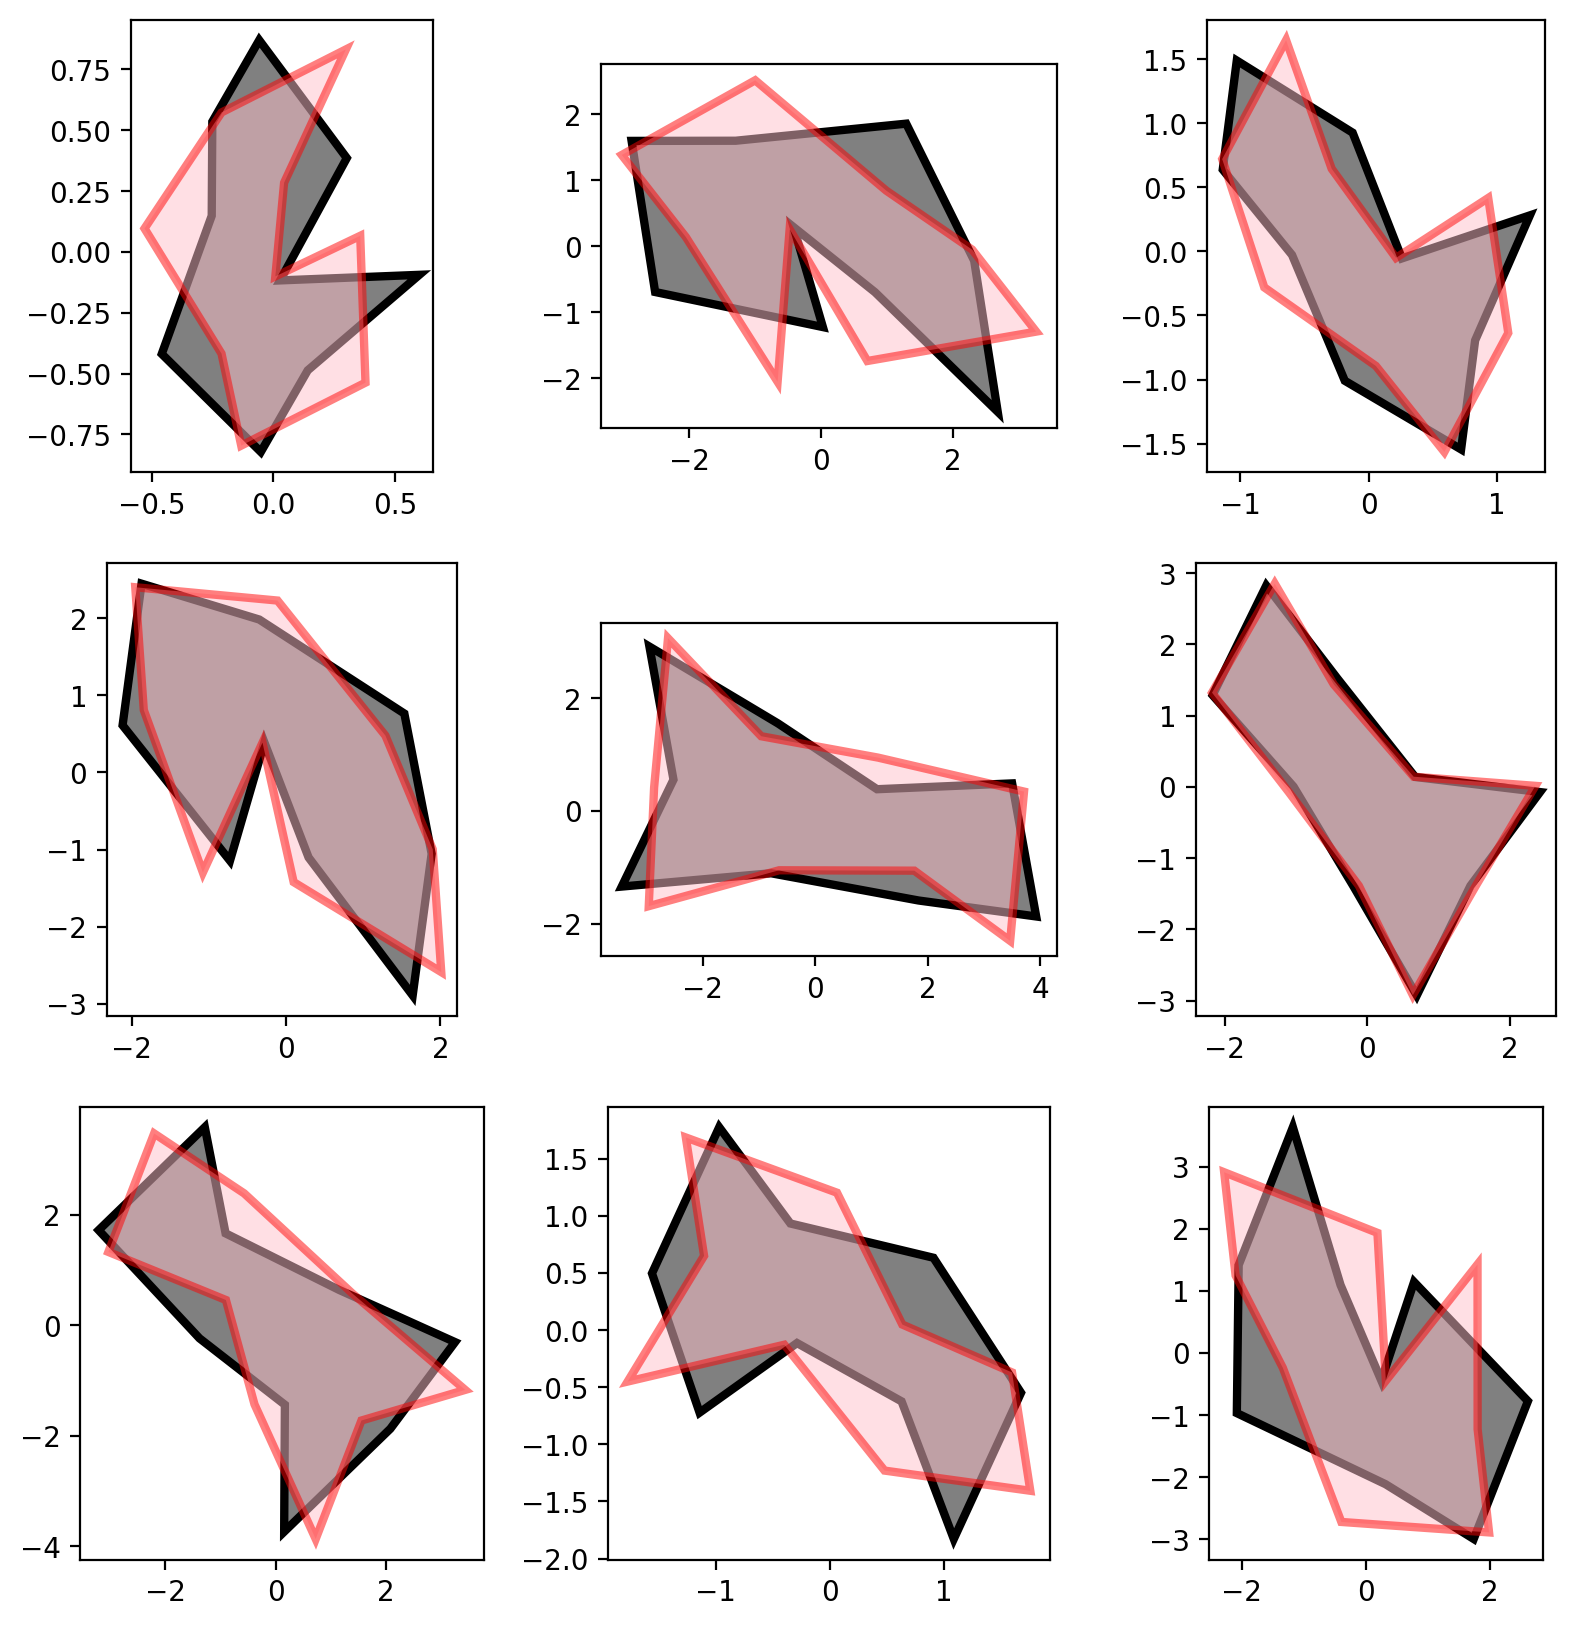

In [13]:
perimeters_1, perimeters_2 = isospectral['perimeters'], isospectral['twin_perimeters']

N_v = perimeters_1.shape[1]
idx = preprocessing.augment(np.arange(N_v, dtype=float)[:, None])[..., 0].astype(int)

key = random.PRNGKey(334)
indices = random.choice(key, perimeters_1.shape[0], shape=(9,))

fig, ax = plt.subplots(3, 3, figsize=(10, 10))
ax = ax.reshape(-1,)
for i in range(9):
    v1, v2 = get_best_alignment(perimeters_1[indices[i]], perimeters_2[indices[i]], idx)
    ax[i].fill(v2[:, 0], v2[:, 1], facecolor="grey", edgecolor="black", linewidth=3)
    ax[i].fill(v1[:, 0], v1[:, 1], facecolor="pink", edgecolor="red", linewidth=3, alpha=0.5)
    ax[i].set_aspect("equal")

In [14]:
i = 0
n_elements = 4000
v1, v2 = get_best_alignment(perimeters_1[indices[i]], perimeters_2[indices[i]], idx)
a1 = polygon_area(v1) / n_elements
a2 = polygon_area(v2) / n_elements
s1, s2 = spectrum.get_drum_spectrum(np.array(v1), a=a1)[0], spectrum.get_drum_spectrum(np.array(v2), a=a2)[0]
s_gt = isospectral_spectrum[indices[i]]
s_gt_ = isospectral_spectrum[17]
rel_error_1 = np.linalg.norm(s1 - s2) / np.linalg.norm(s1)
rel_error_2 = np.linalg.norm(s1 - s_gt) / np.linalg.norm(s1)
rel_error_3 = np.linalg.norm(s2 - s_gt) / np.linalg.norm(s2)
rel_error_4 = np.linalg.norm(s_gt - s_gt_) / np.linalg.norm(s_gt)
print("error isospectral", rel_error_1)
print("error 1 vs gt", rel_error_2)
print("error 2 vs gt", rel_error_3)
print("error between distinct drums", rel_error_4)

error isospectral 0.00022349184283950677
error 1 vs gt 0.00023206829240987137
error 2 vs gt 0.00017592572880522413
error between distinct drums 0.37918388816900445
